# Vape & Cigarette Detection using YOLO11
Data: https://universe.roboflow.com/stelar/vape-cigarette-detection-2



In [ ]:
!nvidia-smi

Wed Oct 28 11:14:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 01: Install & Import

In [ ]:
!pip install -q ultralytics roboflow

In [ ]:
import os, glob, subprocess
import ultralytics
from ultralytics import YOLO
from IPython.display import Image, HTML, display
from base64 import b64encode

ultralytics.checks()

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.6/112.6 GB disk)


## Step 02: Download Dataset from Roboflow

In [ ]:
from roboflow import Roboflow

rf = Roboflow(api_key="LRQkxKBqaMnDewJlXzTJ")
project = rf.workspace("menna-nasser").project("vape-cigarette-detection-2-079ak")
version = project.version(2)
dataset = version.download("yolov11")

print(dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to vape-cigarette-detection-2-2 in yolov11:: 100%|██████████| 2302/2302 [00:00<00:00, 7197.58it/s]

/content/vape-cigarette-detection-2-2


In [ ]:
for s in ["train", "valid", "test"]:
    p = f"{dataset.location}/{s}/images"
    print(s, len(os.listdir(p)) if os.path.exists(p) else "مش موجود")

train 804
valid 230
test 115


## Step 03: Train YOLO11

In [ ]:
!yolo task=detect mode=train data={dataset.location}/data.yaml model="yolo11n.pt" epochs=50 imgsz=640

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/vape-cigarette-detection-2-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optim

## Step 04: Examine Training Results

Training folder: /content/runs/detect/train
confusion_matrix.png


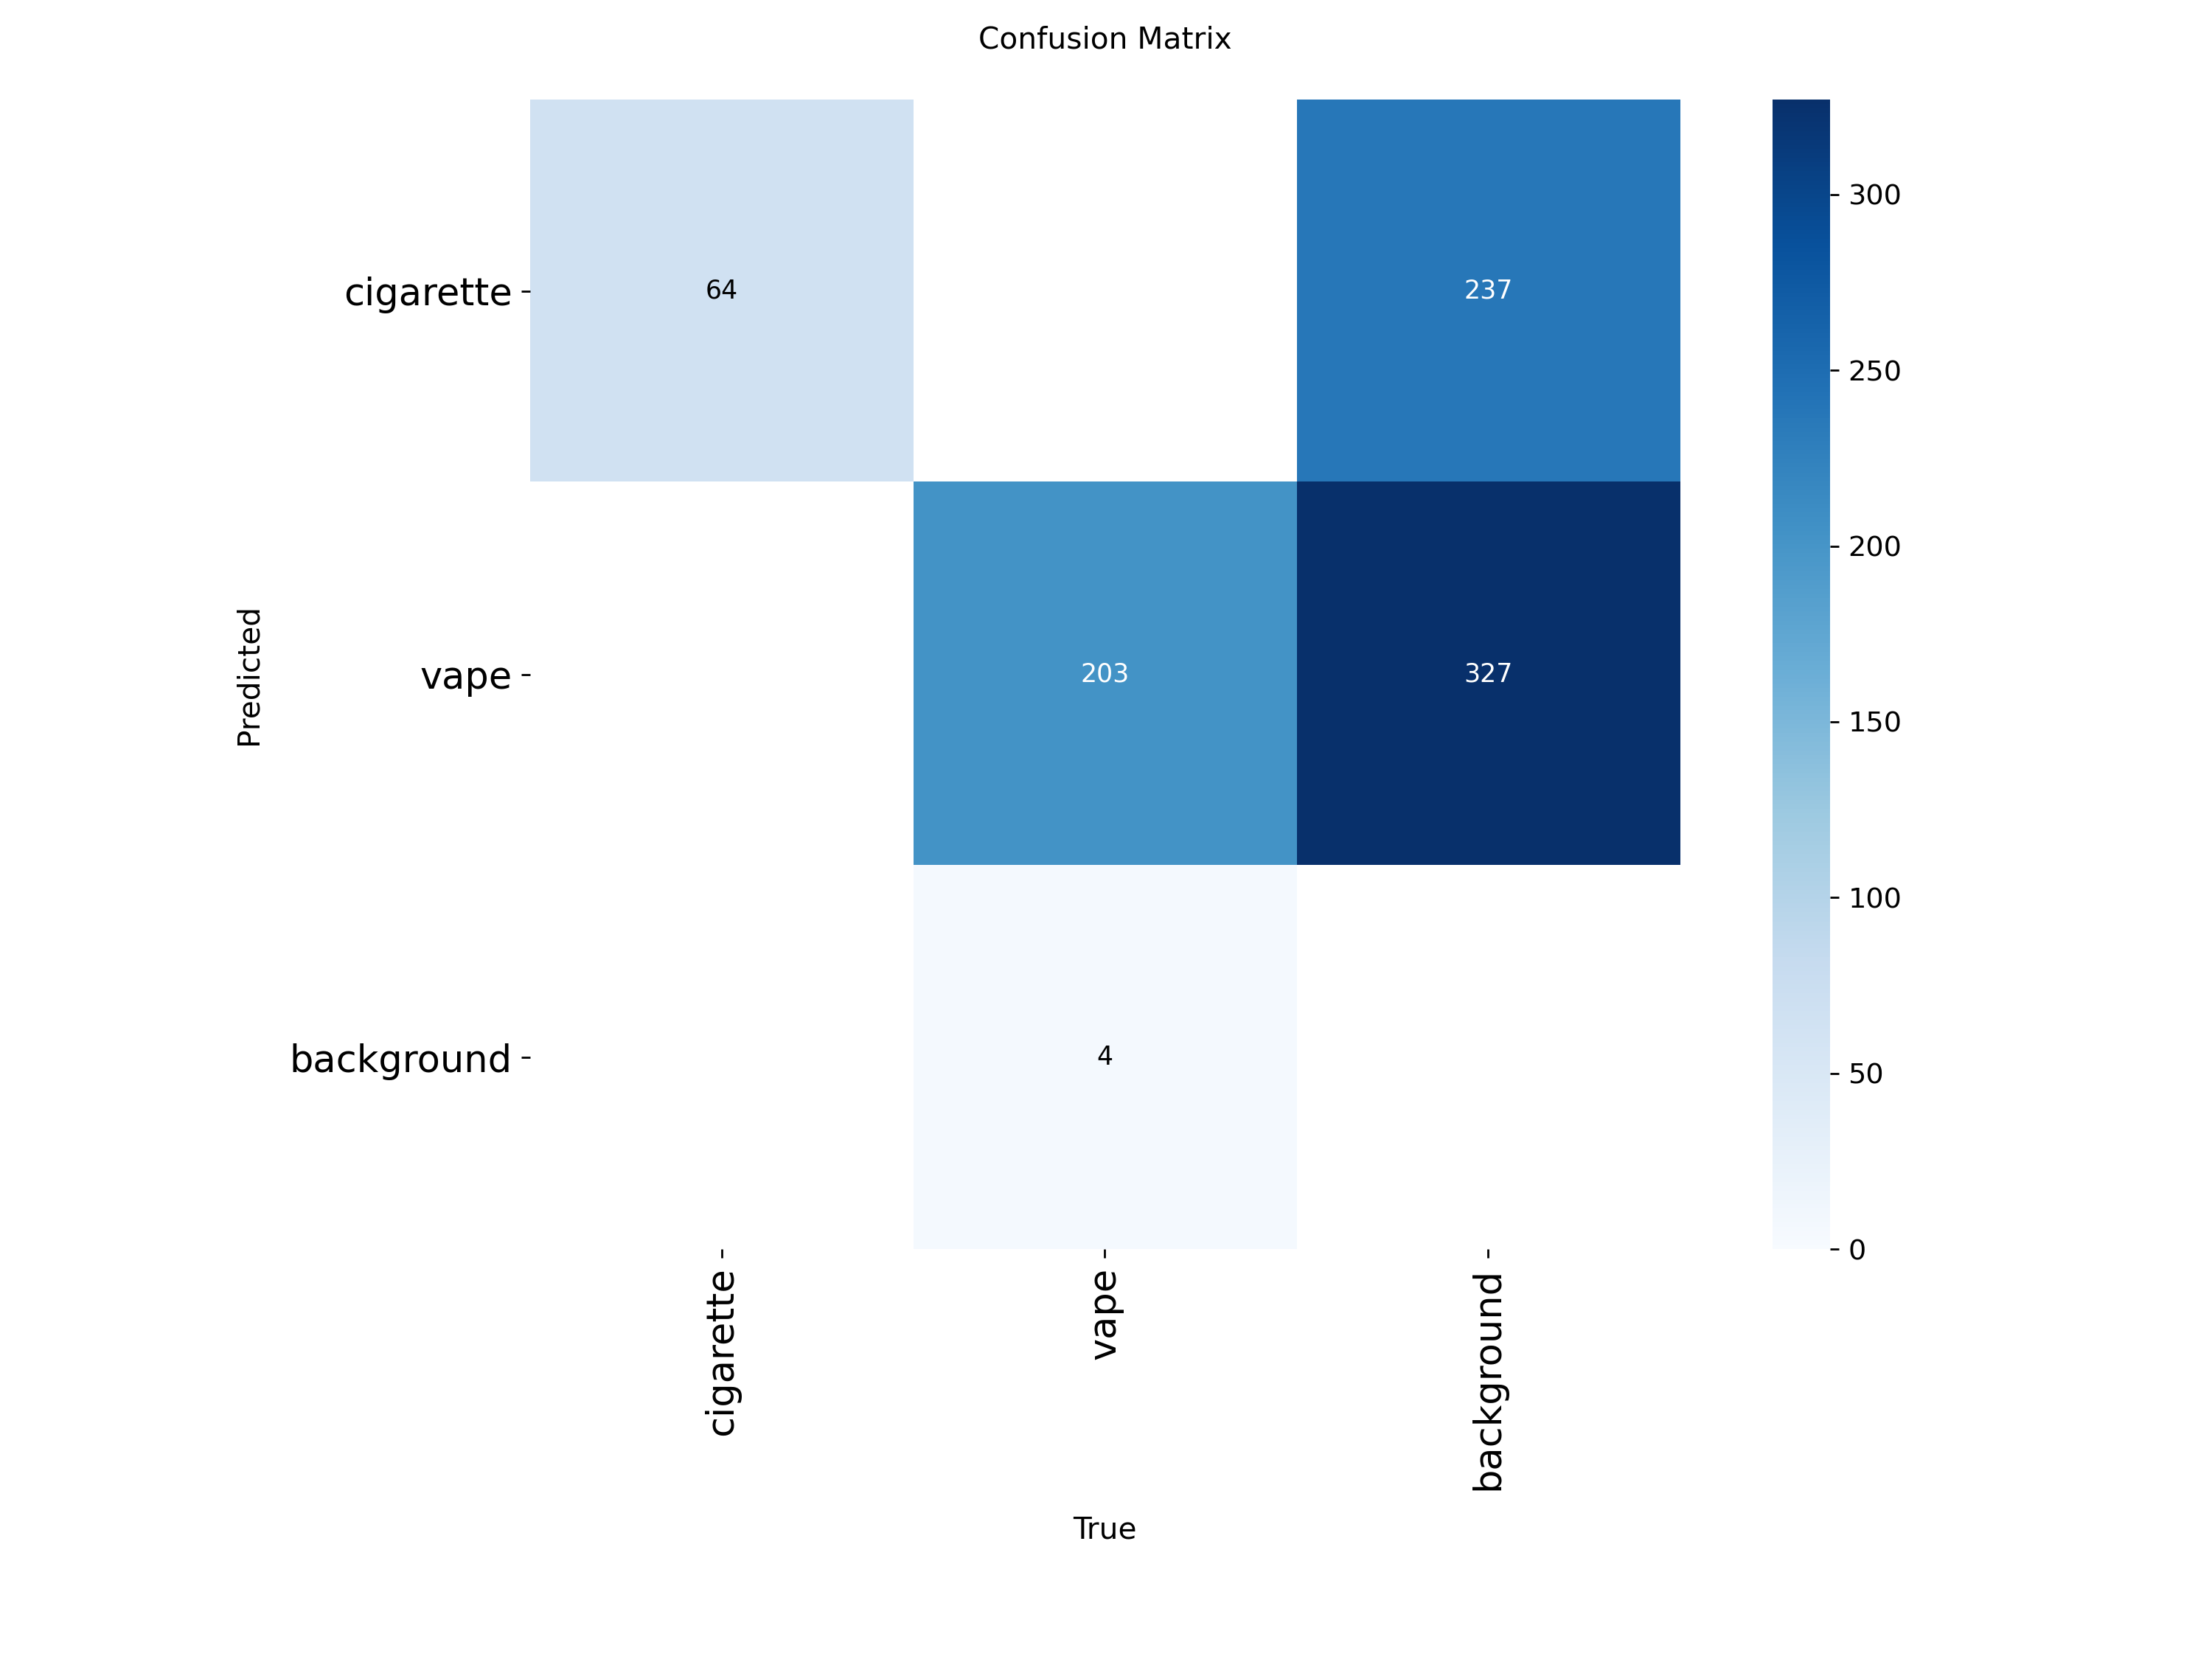

labels.jpg


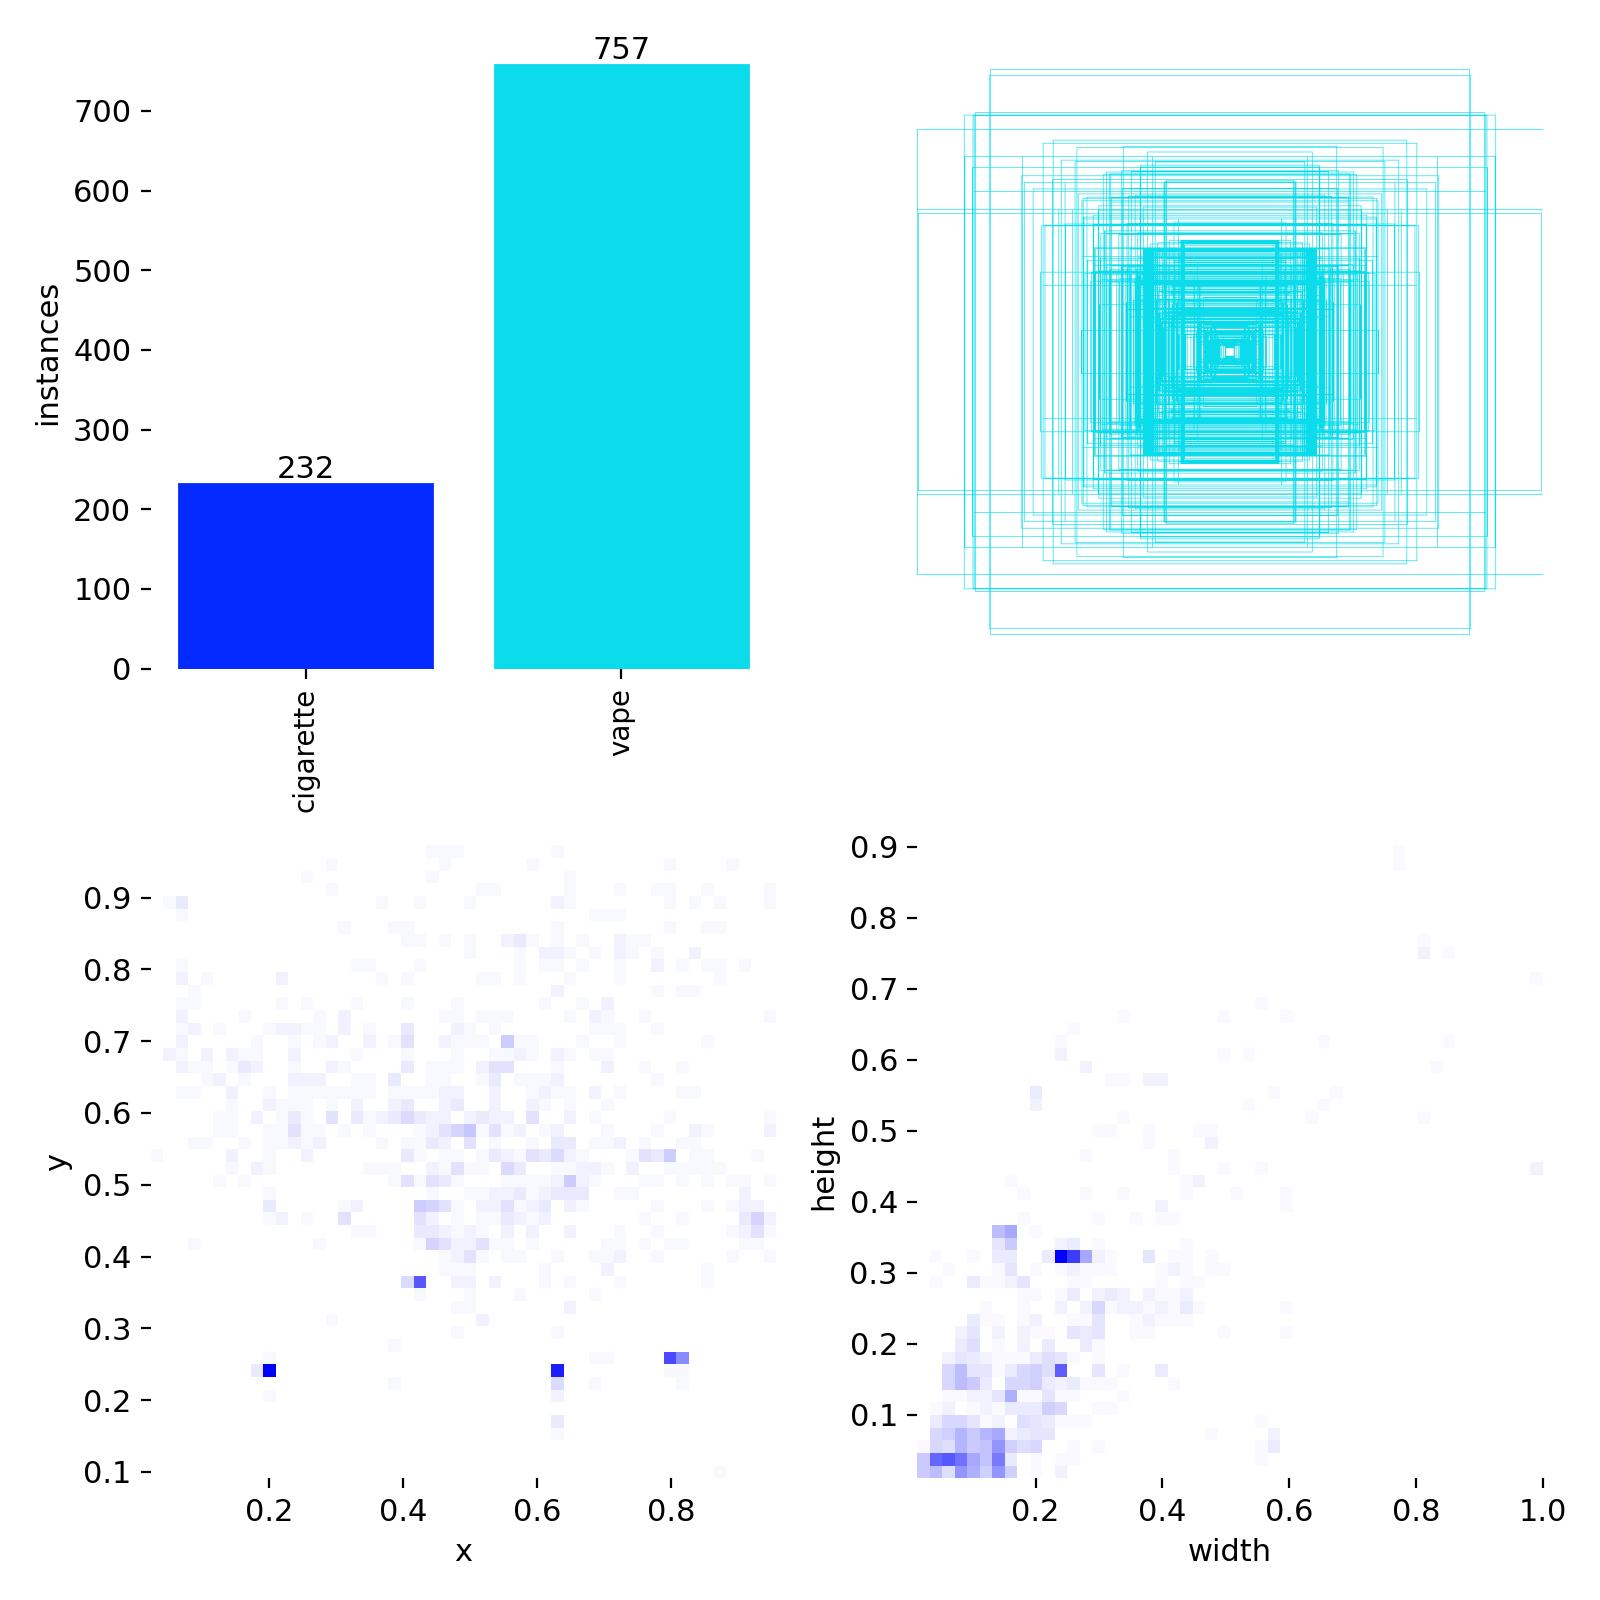

results.png


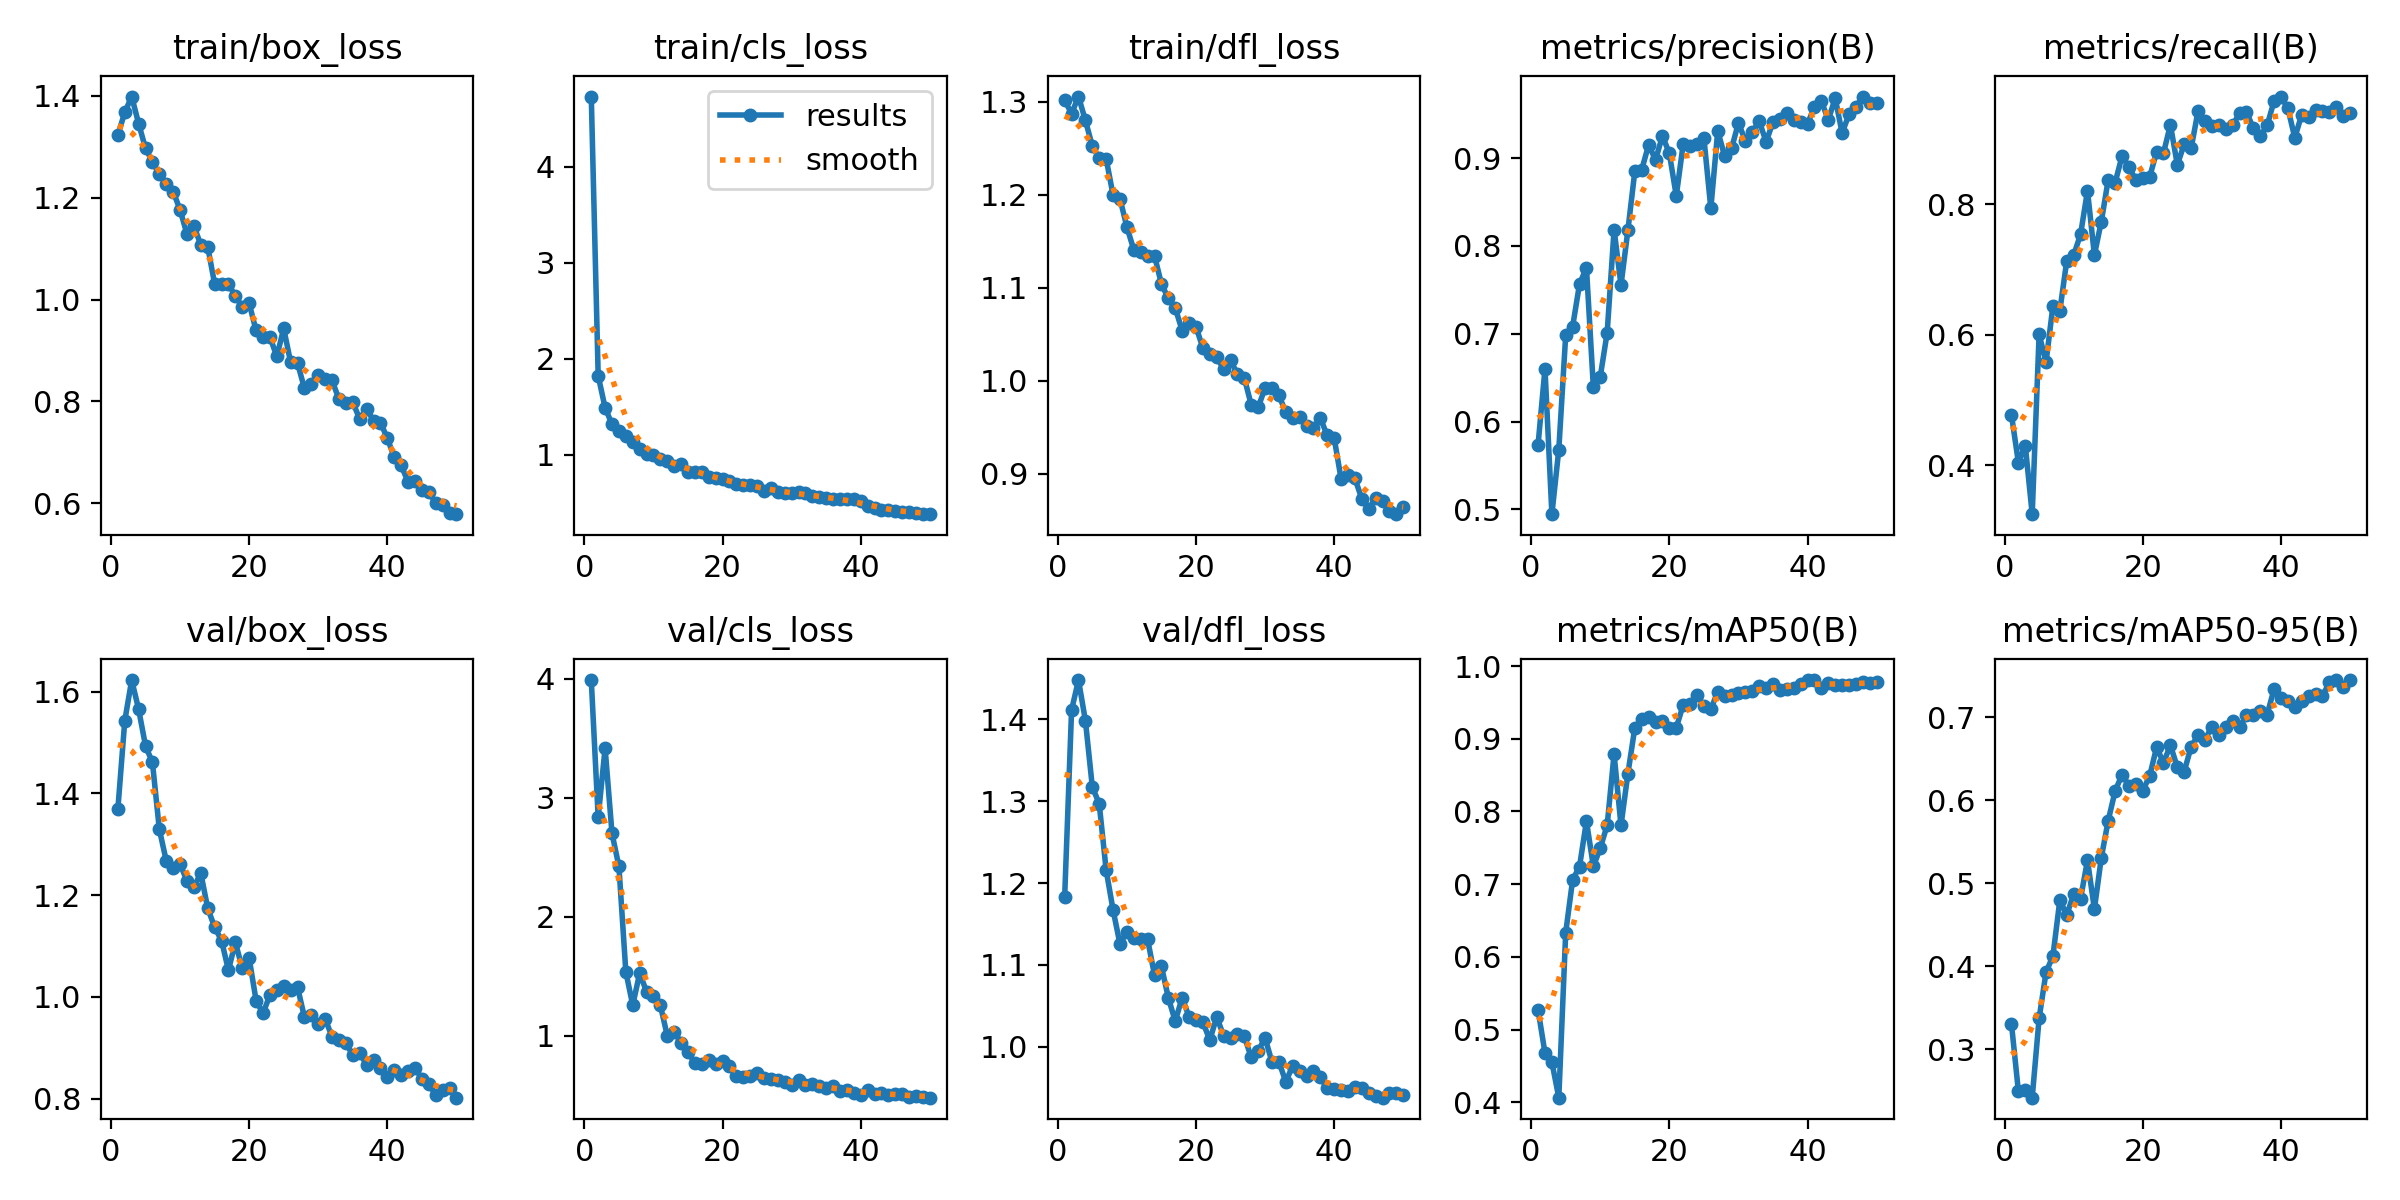

train_batch0.jpg


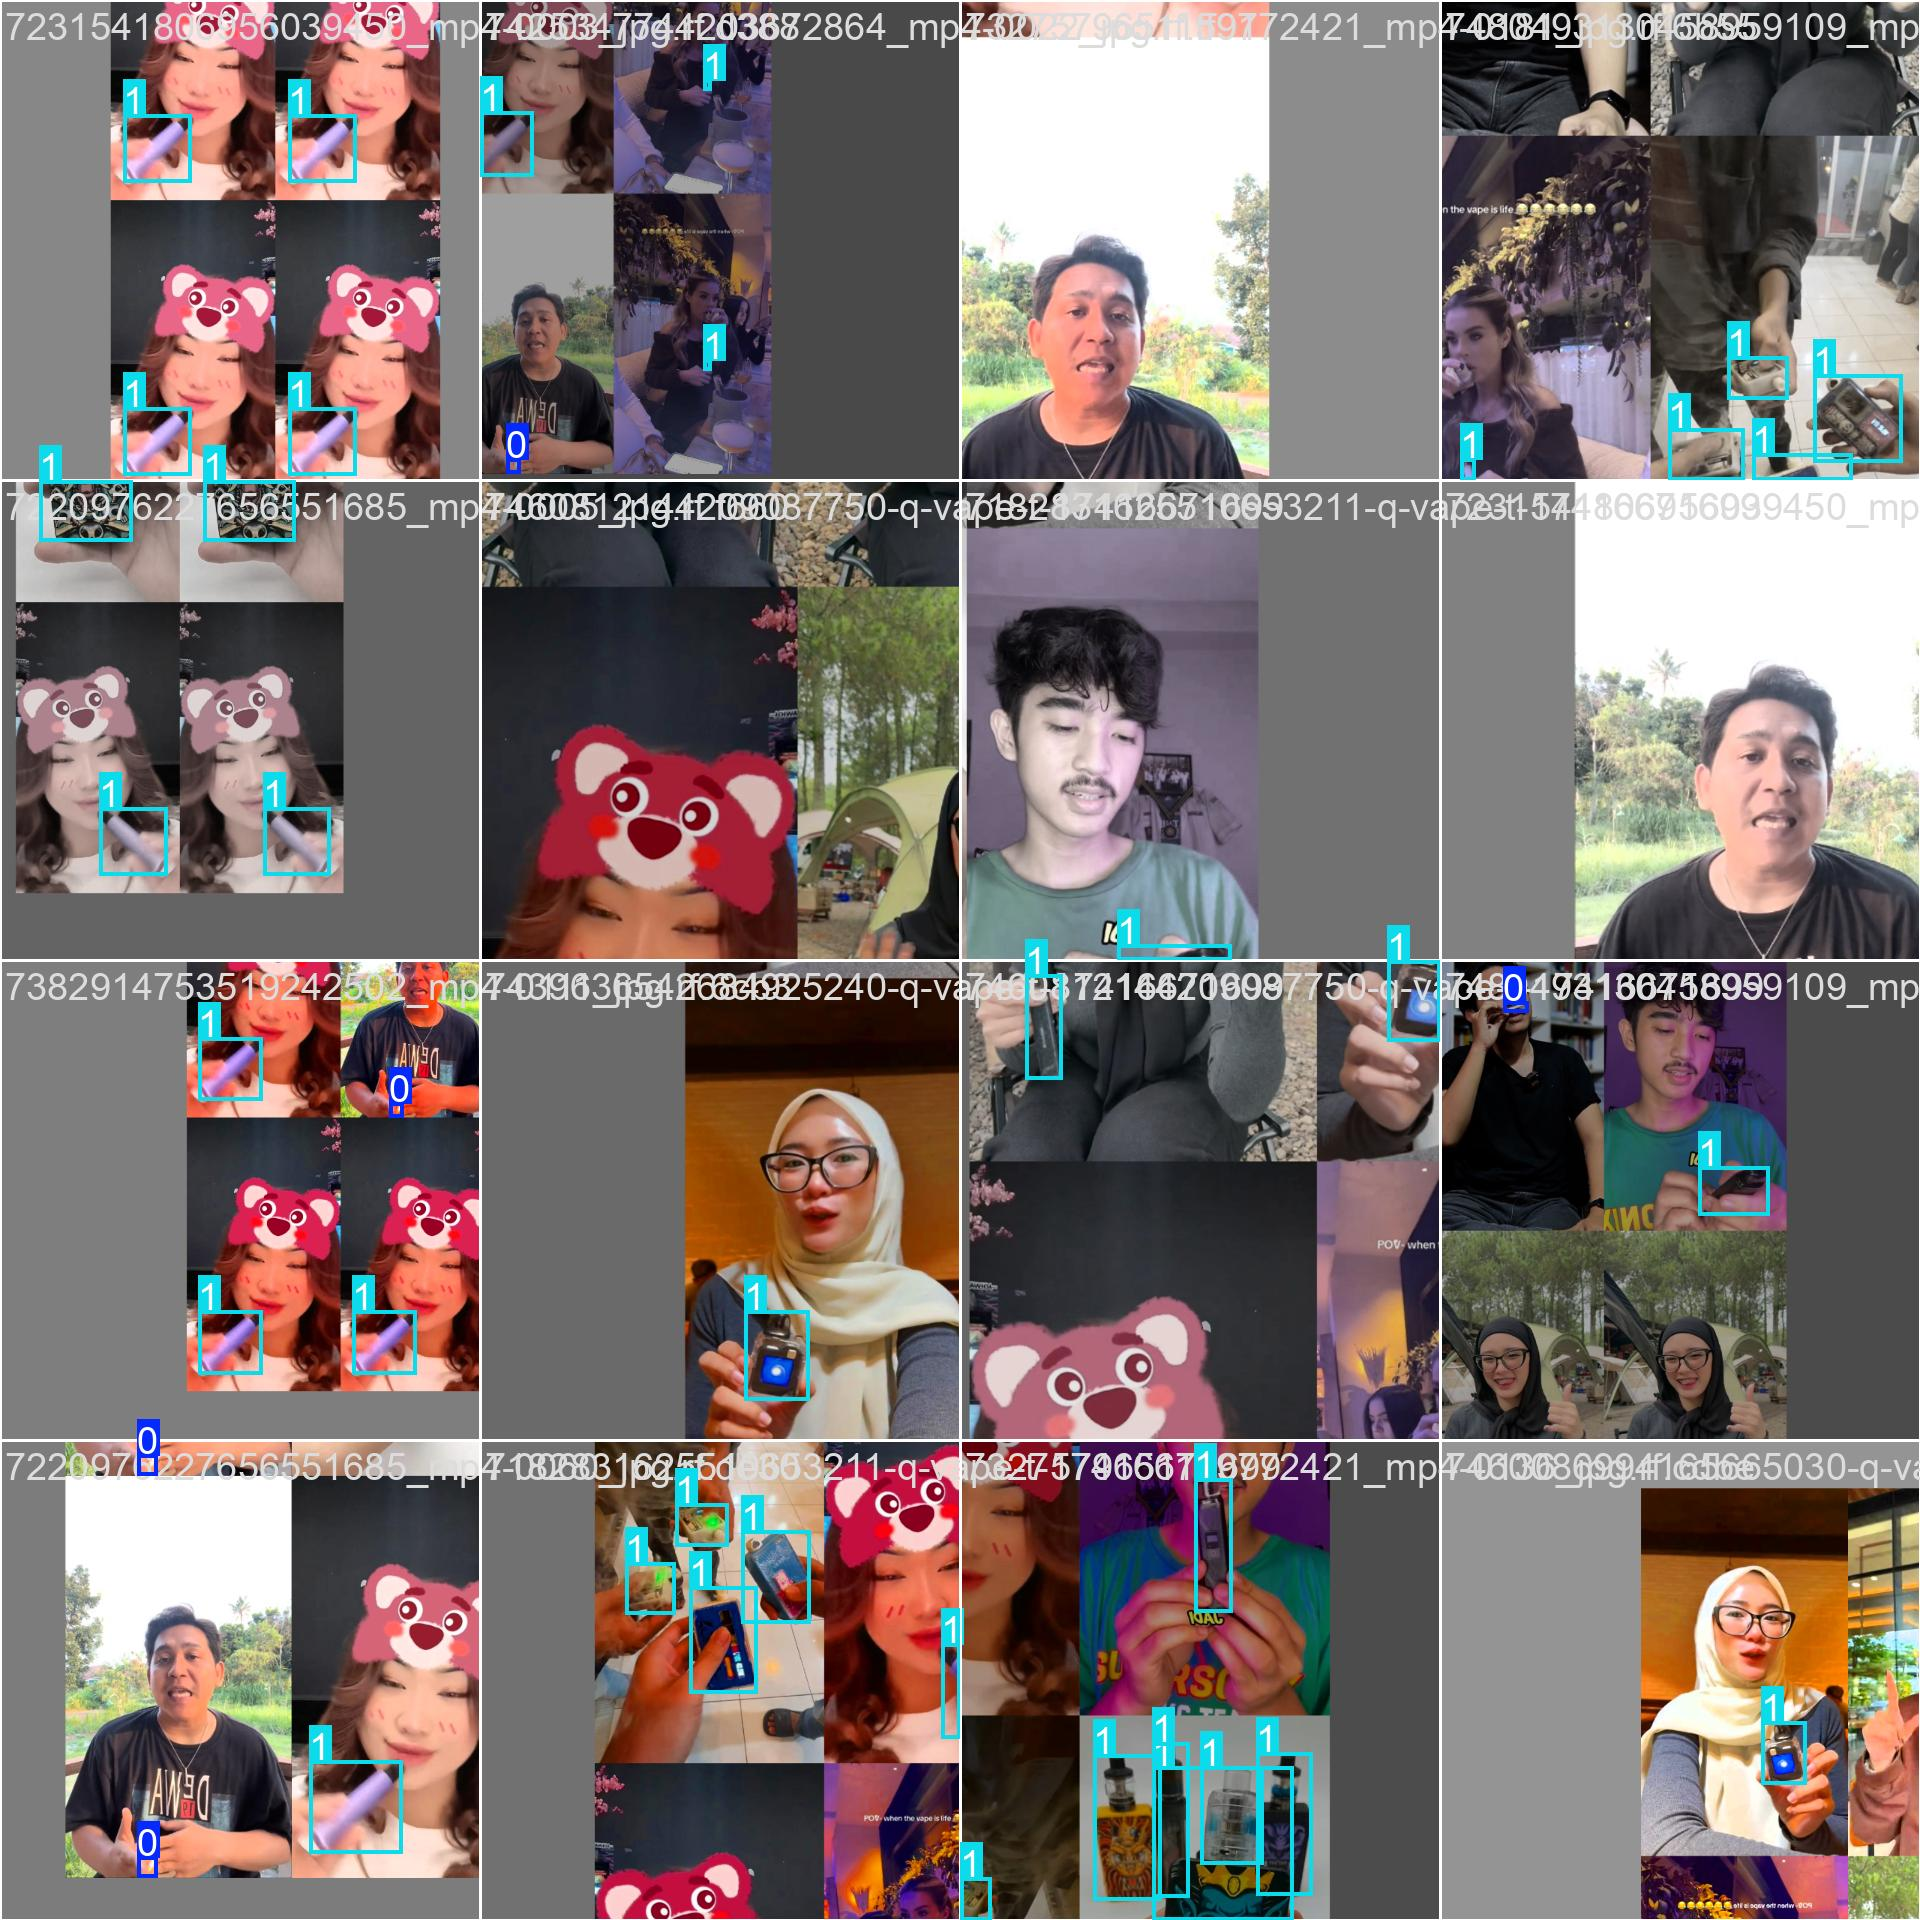

val_batch0_pred.jpg


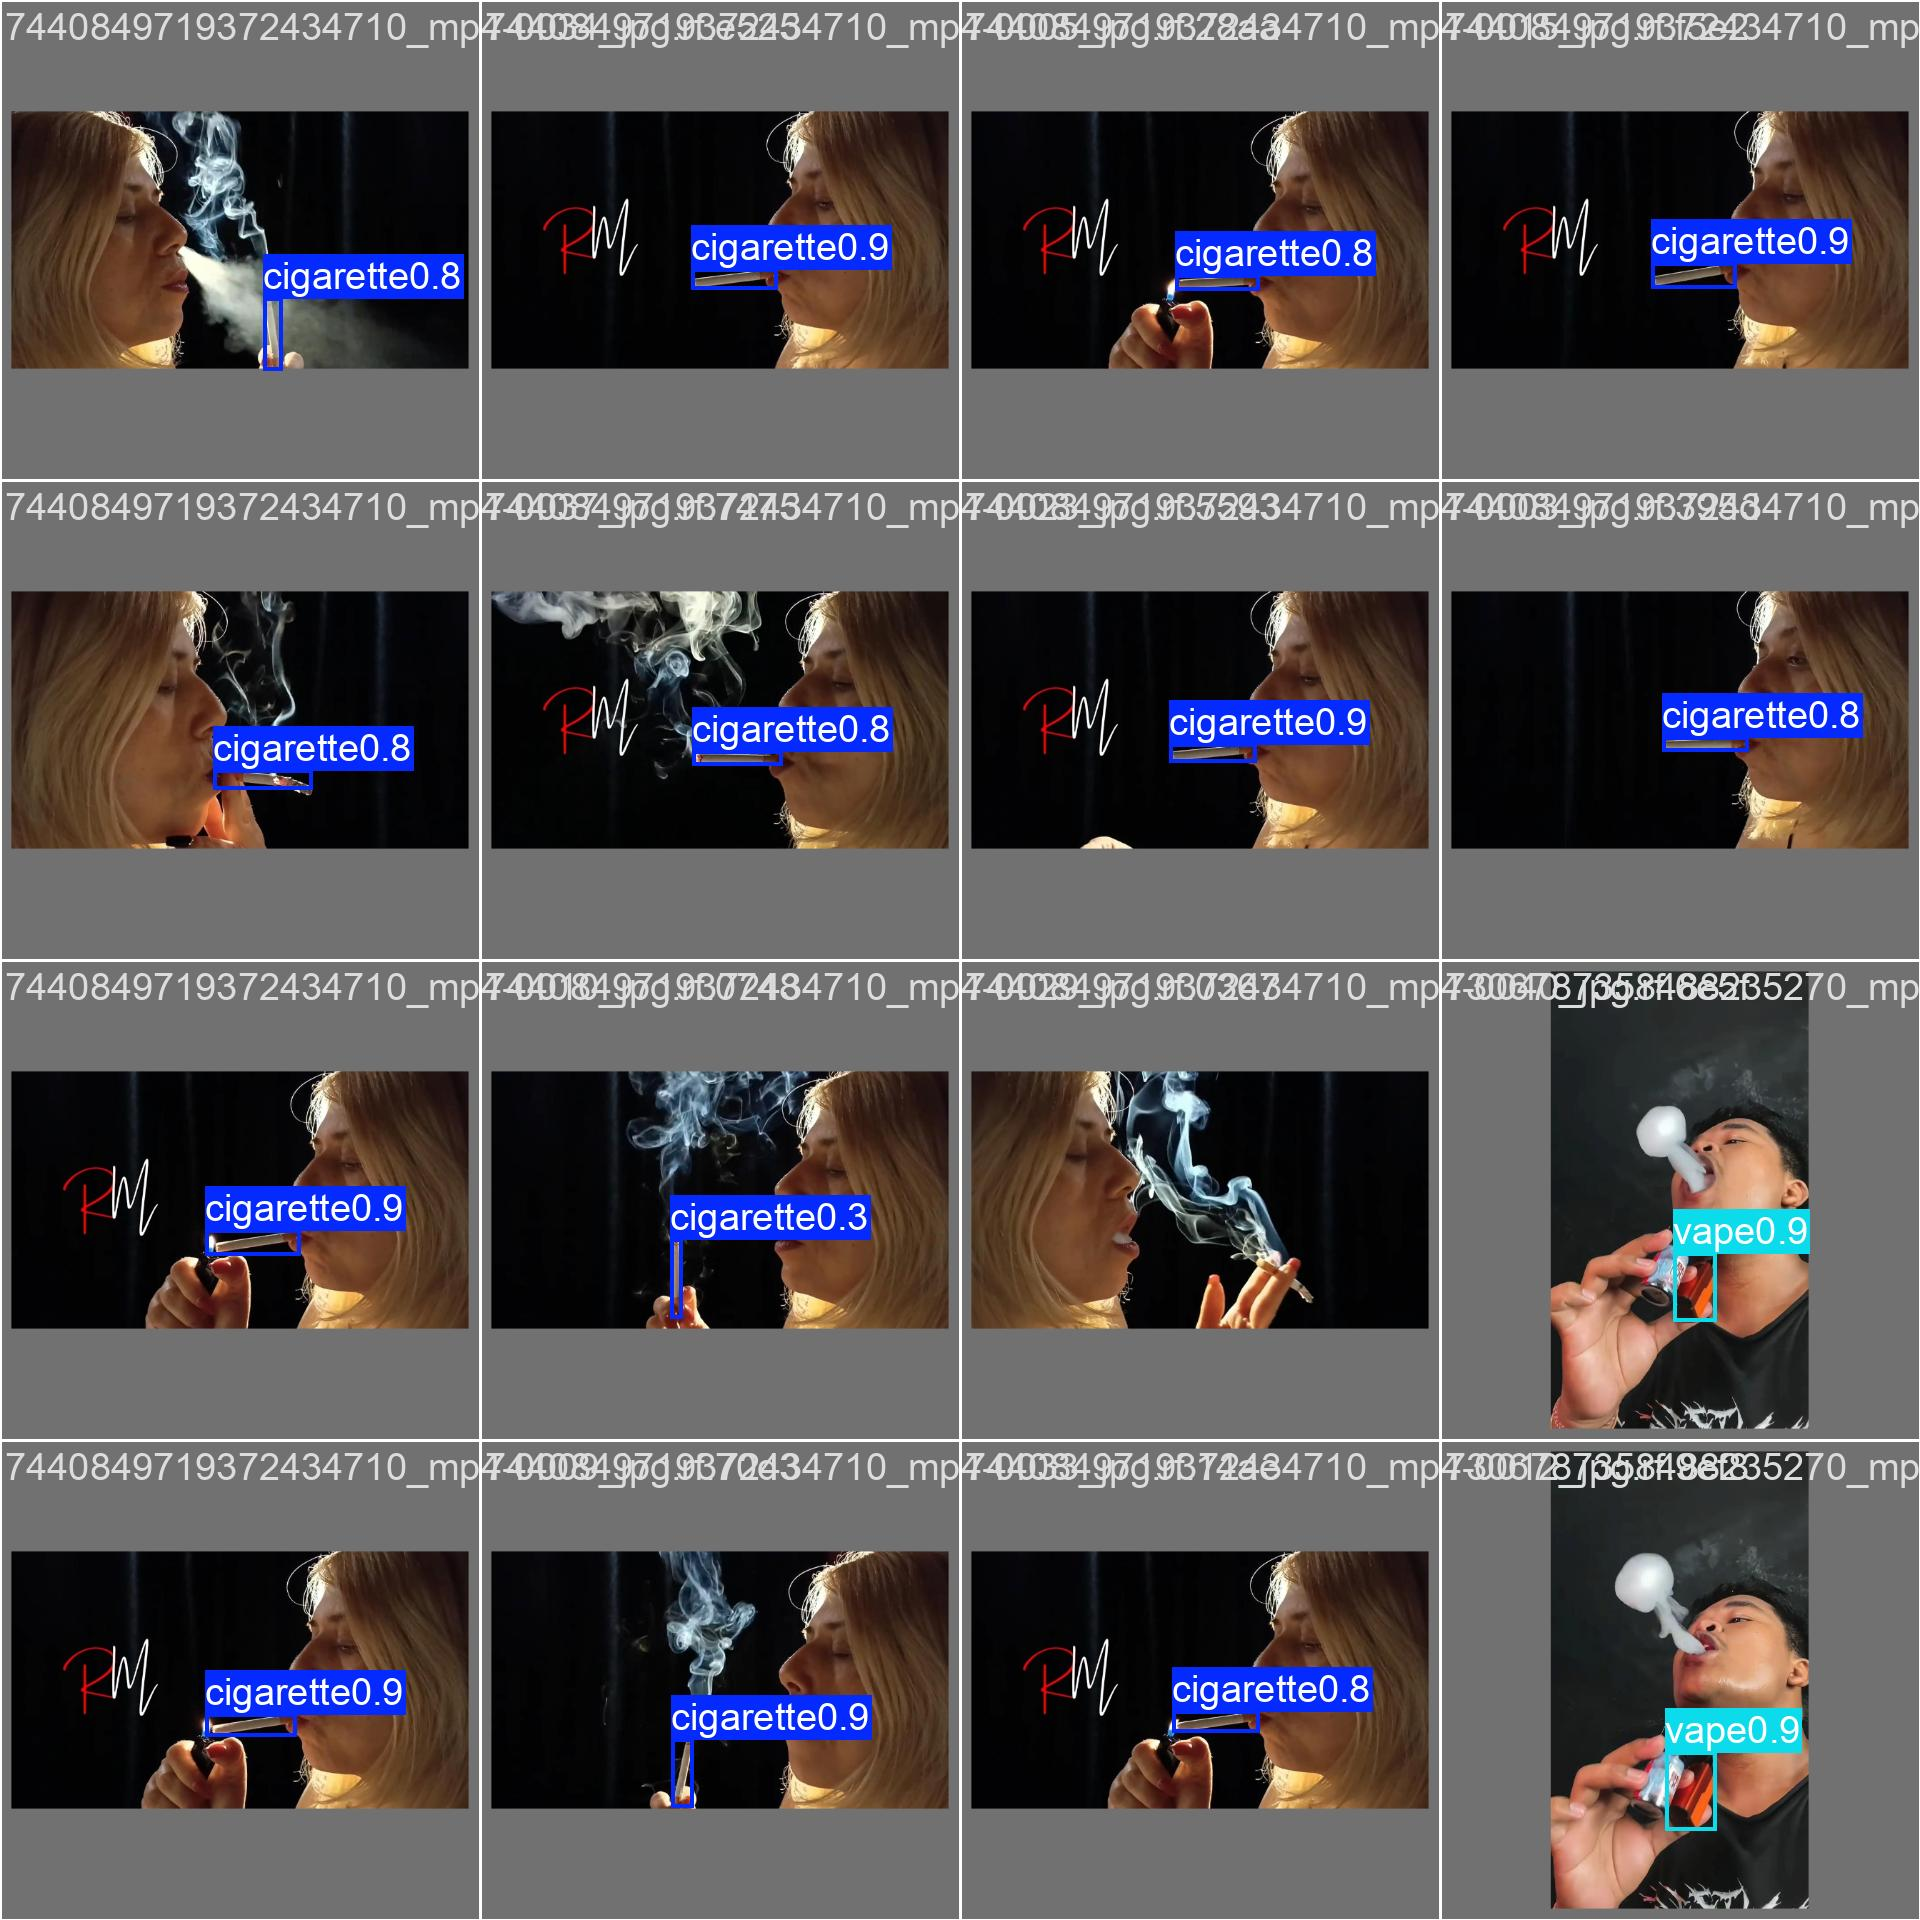

val_batch1_pred.jpg


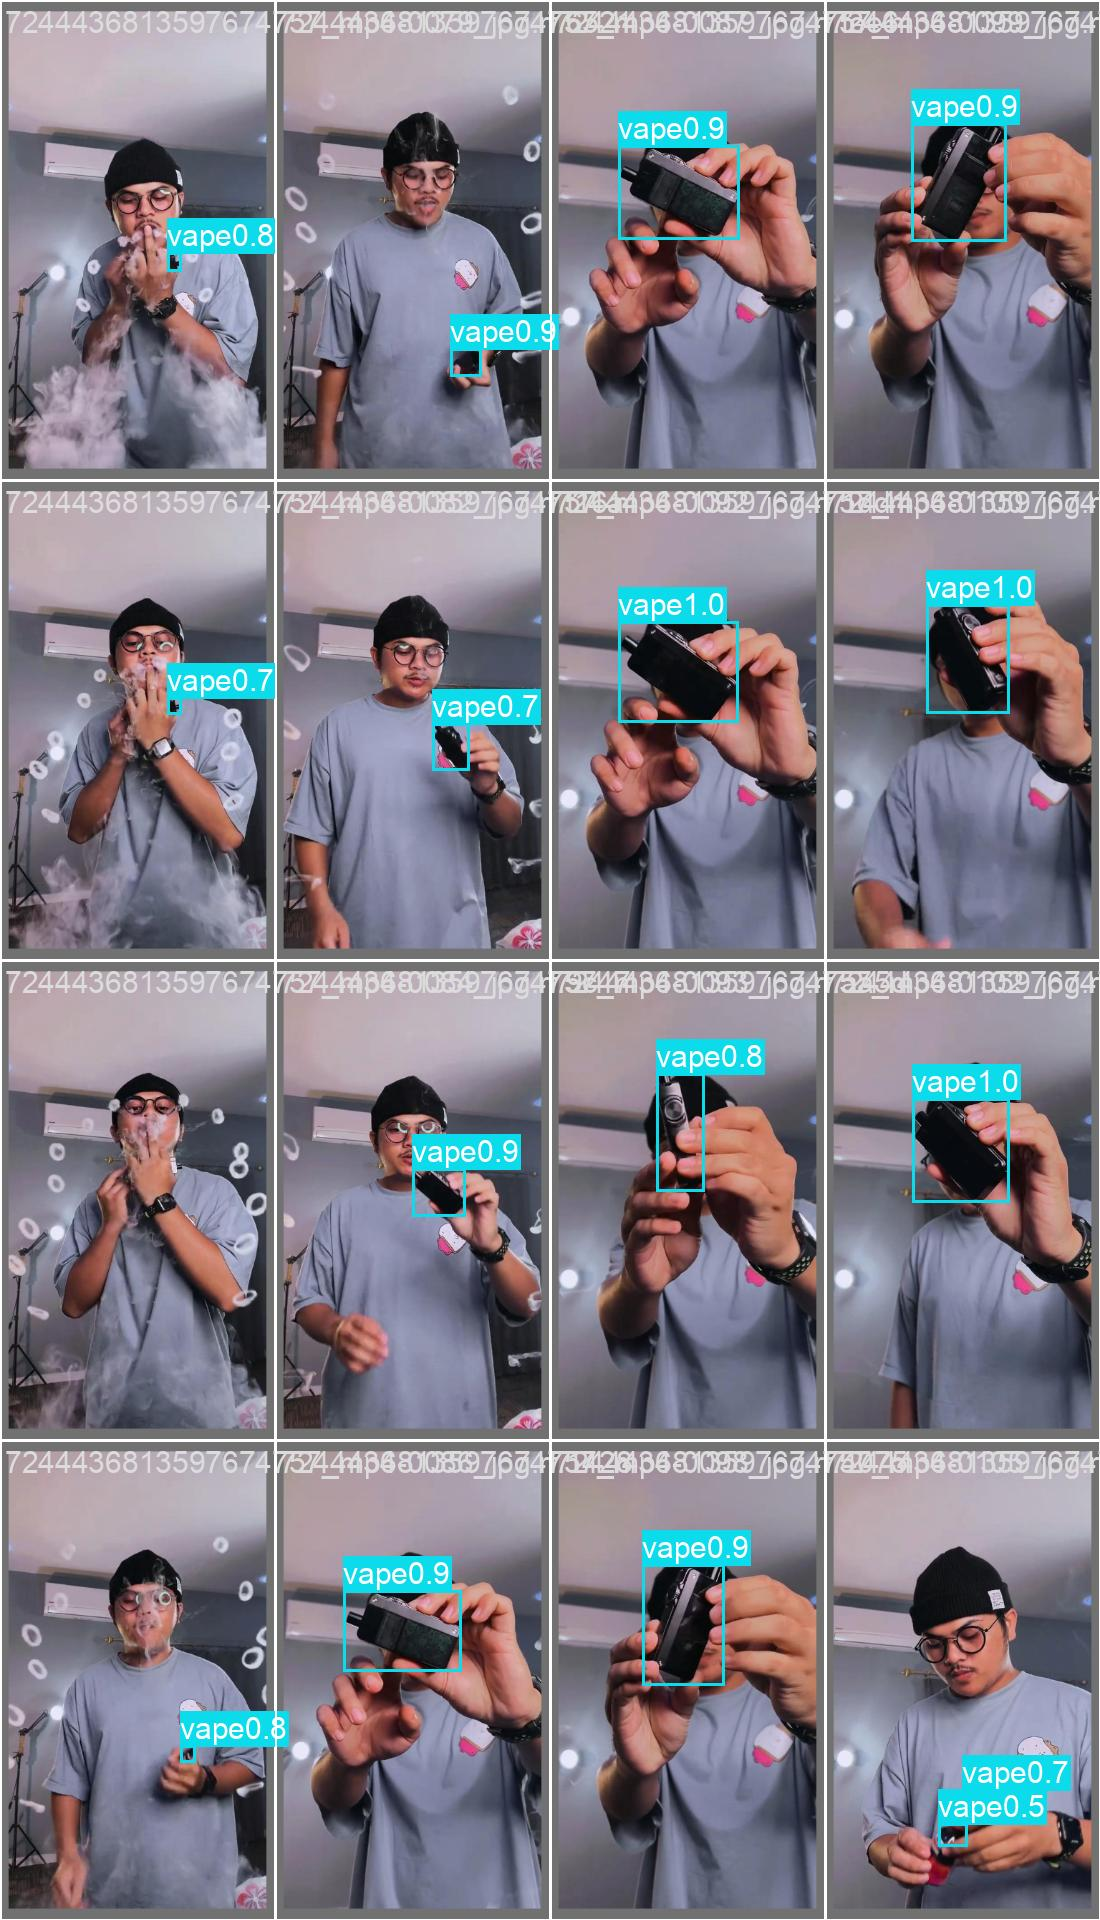

In [ ]:
train_dir = max(glob.glob('/content/runs/detect/train*'), key=os.path.getmtime)
print("Training folder:", train_dir)

for name in ["confusion_matrix.png", "labels.jpg", "results.png", "train_batch0.jpg", "val_batch0_pred.jpg", "val_batch1_pred.jpg"]:
    path = f"{train_dir}/{name}"
    if os.path.exists(path):
        print(name)
        display(Image(path, width=600))

## Step 05: Inference on Test Images

In [ ]:
best_model = os.path.join(train_dir, "weights", "best.pt")
print("Model:", best_model)

!yolo task=detect mode=predict model={best_model} source={dataset.location}/test/images conf=0.4 save=True project=/content/runs/detect name=test_pred exist_ok=True

Model: /content/runs/detect/train/weights/best.pt
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs

image 1/115 /content/vape-cigarette-detection-2-2/test/images/7182831625510653211-q-vape-t-1741667169973_mp4-0010_jpg.rf.77012ae5c6d34e2735f16f8c0dbccdc0.jpg: 640x384 4 vapes, 9.0ms
image 2/115 /content/vape-cigarette-detection-2-2/test/images/7182831625510653211-q-vape-t-1741667169973_mp4-0017_jpg.rf.c6732dfa4cc17669d0f5cfffc0b17ccc.jpg: 640x384 4 vapes, 9.8ms
image 3/115 /content/vape-cigarette-detection-2-2/test/images/7182831625510653211-q-vape-t-1741667169973_mp4-0022_jpg.rf.c0a389b9ffb3d4376f402a4d7edb2f84.jpg: 640x384 3 vapes, 9.2ms
image 4/115 /content/vape-cigarette-detection-2-2/test/images/7220976227656551685_mp4-0029_jpg.rf.a1f5e7f92e97d2fb63ba96efed5f0dec.jpg: 640x384 5 vapes, 9.1ms
image 5/115 /content/vape-cigarette-detection-2-2/test/images/722097622765655

عدد الصور: 115


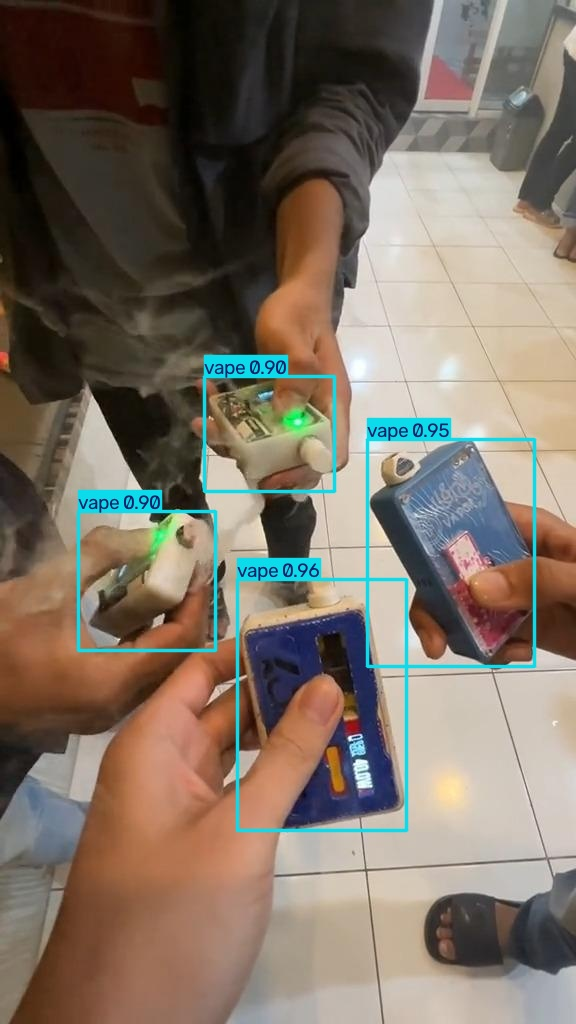

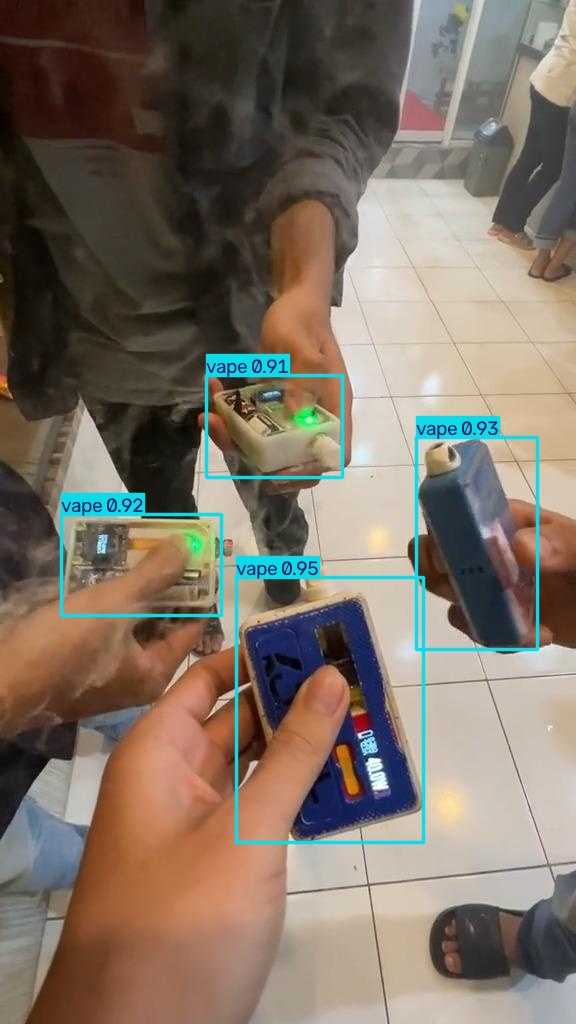

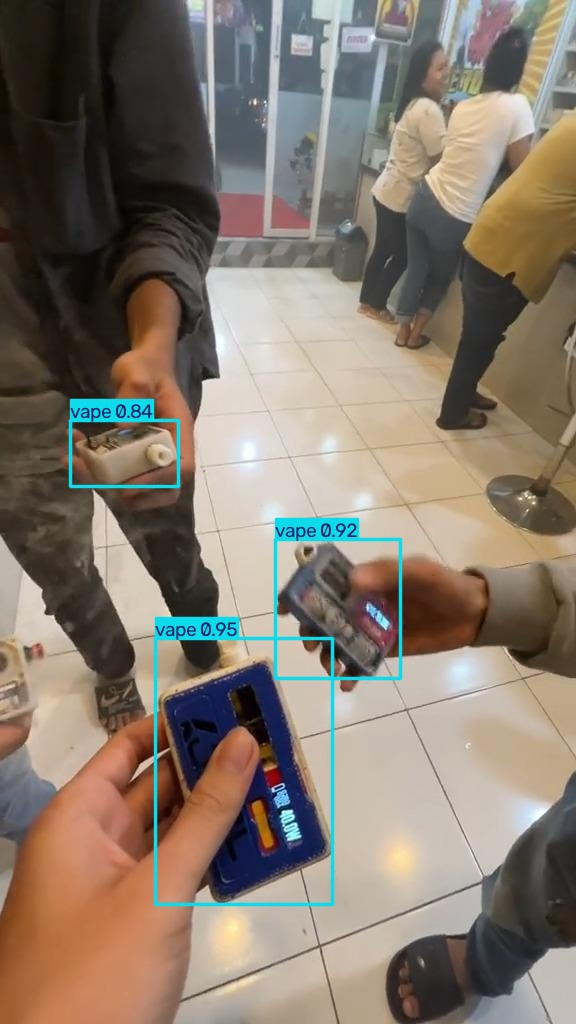

In [ ]:
imgs = sorted(glob.glob('/content/runs/detect/test_pred/*.jpg'))
print("num: ", len(imgs))
for img in imgs[:3]:
    display(Image(img, width=600))

## Step 06: Inference on Video


In [ ]:
videos = [f for ext in ("mp4", "mov", "avi", "mkv") for f in glob.glob(f"/content/*.{ext}")]
assert videos,
video_path = videos[0]
print("video : ", video_path)
print("video size : ", round(os.path.getsize(video_path) / 1024 / 1024, 2), "MB")

الفيديو: /content/my_video.mp4
حجم الفيديو: 11.44 MB


In [ ]:
!yolo task=detect mode=predict model={best_model} source={video_path} conf=0.4 save=True project=/content/runs/detect name=video_pred exist_ok=True

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs

video 1/1 (frame 1/304) /content/my_video.mp4: 384x640 (no detections), 8.3ms
video 1/1 (frame 2/304) /content/my_video.mp4: 384x640 (no detections), 14.3ms
video 1/1 (frame 3/304) /content/my_video.mp4: 384x640 (no detections), 20.0ms
video 1/1 (frame 4/304) /content/my_video.mp4: 384x640 (no detections), 14.2ms
video 1/1 (frame 5/304) /content/my_video.mp4: 384x640 (no detections), 14.4ms
video 1/1 (frame 6/304) /content/my_video.mp4: 384x640 (no detections), 17.2ms
video 1/1 (frame 7/304) /content/my_video.mp4: 384x640 (no detections), 14.8ms
video 1/1 (frame 8/304) /content/my_video.mp4: 384x640 (no detections), 17.5ms
video 1/1 (frame 9/304) /content/my_video.mp4: 384x640 (no detections), 18.2ms
video 1/1 (frame 10/304) /content/my_video.mp4: 384x640 1 cigarette, 18.4ms
video 1/1 (frame 11/304) /content/my_video.mp4

In [ ]:
!ls -lh /content/runs/detect/video_pred

total 51M
-rw-r--r-- 1 root root 51M Oct 28 11:34 my_video.avi


## Step 07: Compress & Show the Result Video


In [ ]:
files = glob.glob('/content/runs/detect/video_pred/*.avi') + glob.glob('/content/runs/detect/video_pred/*.mp4')
assert files, ""
save_path = files[0]
small_path = "/content/video_small.mp4"

subprocess.run(["ffmpeg", "-y", "-i", save_path, "-vcodec", "libx264", "-pix_fmt", "yuv420p",
                "-crf", "30", "-preset", "fast", "-vf", "scale=-2:480", "-an", small_path], check=True)

print("", round(os.path.getsize(small_path) / 1024 / 1024, 2), "MB")

data_url = "data:video/mp4;base64," + b64encode(open(small_path, 'rb').read()).decode()
HTML(f"""
<video width=500 controls>
  <source src="{data_url}" type="video/mp4">
</video>
""")

حجم الفيديو بعد الضغط: 0.23 MB
